# İstanbul'da İntihar İstatistikleri (2009-2025): Metropol Stresi Hipotezi

Merhaba! Bu dosyayı inceleyen kişiye kısa bir not: Bu çalışmayı bir hikâye gibi kurdum. Her kod bloğundan **önce** ne yapacağımı ve nedenini yazdım,
kodun **altında** da çıkan sonucu kendi cümlelerimle yorumladım. Yani yalnızca yazı (markdown) hücrelerini yukarıdan aşağıya okusanız bile
çalışmanın ne yaptığını ve ne bulduğunu anlayabilirsiniz.

## 1. Amacım ve cevaplamaya çalışacağım sorular

Çalışmanın çıkış noktası, günlük hayatta sık duyduğumuz bir düşünce:

> *"İstanbul metropol stresi ve yaşam pahalılığı nedeniyle Türkiye ortalamasından daha yüksek bir intihar riskine (kaba intihar hızı) sahiptir."*

Bu cümleyi bir **hipotez** olarak alıyorum ve veriyle sınayacağım. Ardından İstanbul'u daha yakından tanımak için üç alt soru daha soruyorum:

| No | Soru |
|---|---|
| 1 | Ana hipotez: İstanbul'un intihar hızı gerçekten Türkiye ortalamasından yüksek mi? |
| 2 | Cinsiyet: Vakalarda erkek/kadın oranı zaman içinde nasıl değişmiş? |
| 3 | Yaş grubu: Vakalar en çok hangi yaş grubunda yoğunlaşıyor ve genç/yaşlı dağılımı nasıl değişmiş? |
| 4 | Yöntem: En sık görülen intihar şekilleri nelerdir? |

## 2. Veri setini tanıyalım

**Veri kaynağı:** TÜİK (Türkiye İstatistik Kurumu) İntihar İstatistikleri (https://veriportali.tuik.gov.tr/tr/press/58233). İlgili 4 Excel tablosunu kullandım:

| Excel dosyası | İçerik |
|---|---|
| `il_ve_cinsiyete_gore_intiharlar.xlsx` | İl ve cinsiyete göre vaka sayısı |
| `illere_gore_kaba_intihar_hizi.xlsx` | İllere göre kaba intihar hızı (100 bin kişide) |
| `il_ve_yas_grubuna_gore_intiharlar.xlsx` | İl ve yaş grubuna göre vaka sayısı |
| `il_ve_sekle_gore_intiharlar.xlsx` | İl ve intihar şekline göre vaka sayısı |

Bu tablolar farklı yılları kapsıyor (cinsiyet ve kaba hız 2009'dan, yaş 2002'den, şekil 2000'den başlıyor). Hepsinin **ortak olduğu yıllar 2009-2025**,
yani toplam 17 yıl. Bu yüzden yalnızca bu yılları ve yalnızca **İstanbul'u** (karşılaştırma için Türkiye'yi) alıp `veri_olustur.py` dosyasıyla tek bir tabloda
birleştirdim. Çıkan dosya: `istanbul_intihar_2009_2025.csv`.

Önce iki kütüphaneyi ve grafik çizmek için matplotlib'i içe aktarıyorum:
- **pandas:** tablolarla (satır/sütun) çalışmamı sağlar.
- **numpy:** sayılarla hızlı hesap yapmamı sağlar (ortalama, en büyük değer gibi).
- **matplotlib:** grafik çizmemi sağlar.

Grafiklerin hepsi aynı boyutta ve ızgaralı görünsün diye iki ayar da yapıyorum.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 4.5)   # grafik boyutu
plt.rcParams["axes.grid"] = True            # arka plana ızgara çiz

Şimdi CSV dosyasını okuyup `veri` adlı bir tabloya (DataFrame) koyuyorum. `shape` tablonun (satır, sütun) sayısını, `head()` ilk 5 satırı gösterir.

In [2]:
veri = pd.read_csv("istanbul_intihar_2009_2025.csv")

print("Tablo boyutu (satır, sütun):", veri.shape)
veri.head()

Tablo boyutu (satır, sütun): (17, 32)


,yil,istanbul_toplam,istanbul_erkek,istanbul_kadin,turkiye_toplam,istanbul_hiz,turkiye_hiz,yas_0_14,yas_15_19,yas_20_24,...,sekil_asarak,sekil_kimyevi_madde,sekil_yuksekten_atlayarak,sekil_suya_atlayarak,sekil_atesli_silah,sekil_yakarak,sekil_kesici_alet,sekil_dogalgaz_tupgaz,sekil_arac_altina_atlayarak,sekil_diger
0,2009,403,315,88,2898,3.146923,4.022809,6,24,33,...,226,11,57,16,77,1.0,4,2.0,2.0,7
1,2010,429,333,96,2933,3.278458,4.010000,7,35,48,...,239,14,79,26,54,NaN,3,2.0,2.0,10
2,2011,387,287,100,2677,2.879472,3.606668,3,34,33,...,203,13,67,18,68,1.0,4,1.0,4.0,8
3,2012,542,395,147,3287,3.944833,4.372416,6,49,68,...,264,14,76,17,93,1.0,7,2.0,1.0,67
4,2013,494,396,98,3252,3.526656,4.270652,6,42,57,...,242,9,59,28,107,2.0,7,7.0,2.0,31


**Sütunların anlamı:** `yil` yıldır. `istanbul_...` ve `turkiye_...` ile başlayan sütunlar vaka sayısını (`_toplam`, `_erkek`, `_kadin`) ve 100 bin kişide intihar hızını (`_hiz`) gösterir.
`yas_...` ile başlayanlar yaş grubuna göre, `sekil_...` ile başlayanlar intihar şekline göre vaka sayısıdır (ör. `yas_20_24` = 20-24 yaş).

Analize başlamadan önce veriyi kontrol ediyorum: **eksik değer** var mı? Eksik değer olursa hesaplarım yanlış çıkabilir.

In [3]:
eksik = veri.isnull().sum()       # her sütundaki boş hücre sayısı
eksik[eksik > 0]                  # sadece boş hücresi olan sütunları göster

yas_bilinmeyen                 9
sekil_yakarak                  4
sekil_dogalgaz_tupgaz          2
sekil_arac_altina_atlayarak    4
dtype: int64

**Yorum:** Eksik değerler yalnızca küçük kategorilerde var. TÜİK tablosunda bu hücreler "-" yani "bilgi yoktur" olarak yazılmış. Bu hücreleri silmiyorum;
pandas toplama ve ortalama işlemlerinde boş hücreleri zaten atlıyor.

Bir uyarı: TÜİK 2012 yılında kayıt kapsamını genişletti (kurumsal kayıtlar da eklendi). Bu yüzden 2012 öncesi ile sonrası arasında küçük bir kırılma olabilir.
Yorumlarda bunu aklımda tutacağım.

## 3. Soru 1: İstanbul'un intihar hızı Türkiye'den yüksek mi?

**Hız** kullanıyorum, çünkü İstanbul'un nüfusu çok büyük. Vaka sayısına bakarsam İstanbul her zaman "çok" görünür. Kaba hız, 100 bin kişiye düşen
vaka sayısıdır; böylece İstanbul ile Türkiye'yi adil kıyaslayabilirim.

Hipotezdeki "belirgin şekilde yüksek" ifadesini sayıya dökmem gerekiyor. Kendime şu kuralı koydum:
**İstanbul'un hızı, Türkiye'den en az %10 yüksek olmalı ve bunu 17 yılın çoğunda (en az 9 yıl) göstermeli.**

İki yeni sütun ekliyorum:
- `fark` = İstanbul hızı - Türkiye hızı. Pozitifse İstanbul daha yüksektir.
- `oran` = İstanbul hızı / Türkiye hızı. 1'den büyükse İstanbul daha yüksektir. Benim kuralıma göre en az **1,10** olmalı.

In [4]:
veri["fark"] = veri["istanbul_hiz"] - veri["turkiye_hiz"]
veri["oran"] = veri["istanbul_hiz"] / veri["turkiye_hiz"]

veri[["yil", "istanbul_hiz", "turkiye_hiz", "fark", "oran"]].round(2)

,yil,istanbul_hiz,turkiye_hiz,fark,oran
0,2009,3.15,4.02,-0.88,0.78
1,2010,3.28,4.01,-0.73,0.82
2,2011,2.88,3.61,-0.73,0.80
3,2012,3.94,4.37,-0.43,0.90
4,2013,3.53,4.27,-0.74,0.83
5,2014,3.13,4.11,-0.98,0.76
6,2015,2.98,4.15,-1.17,0.72
7,2016,3.14,4.03,-0.89,0.78
8,2017,3.38,3.94,-0.57,0.86
9,2018,3.67,4.11,-0.43,0.90


**Yorum:** `fark` sütunu baştan sona negatif, `oran` sütunu baştan sona 1'in altında. Tabloya göre İstanbul her yıl Türkiye'nin altında görünüyor.
Bunu gözle bırakmayıp kodla da sayıyorum. Sonuçları bir **sözlükte (dict)** topluyor, sonra bir **döngü** ile yazdırıyorum.

In [5]:
yuksek_yil = (veri["istanbul_hiz"] > veri["turkiye_hiz"]).sum()
belirgin_yil = (veri["oran"] >= 1.10).sum()

sonuc = {
    "İstanbul'un Türkiye'den yüksek olduğu yıl sayısı": int(yuksek_yil),
    "İstanbul'un en az %10 yüksek olduğu yıl sayısı": int(belirgin_yil),
    "Toplam yıl sayısı": len(veri),
    "İstanbul ortalama hız": round(np.mean(veri["istanbul_hiz"]), 2),
    "Türkiye ortalama hız": round(np.mean(veri["turkiye_hiz"]), 2),
    "En yüksek oran (İstanbul / Türkiye)": round(np.max(veri["oran"]), 2),
}

for baslik, deger in sonuc.items():
    print(baslik, ":", deger)

İstanbul'un Türkiye'den yüksek olduğu yıl sayısı : 0
İstanbul'un en az %10 yüksek olduğu yıl sayısı : 0
Toplam yıl sayısı : 17
İstanbul ortalama hız : 3.42
Türkiye ortalama hız : 4.39
En yüksek oran (İstanbul / Türkiye) : 0.9


**Yorum:** İstanbul 17 yılın **hiçbirinde** Türkiye'nin üstüne çıkmamış. Ortalama hızı 3,42; Türkiye'ninki 4,39. En yüksek oran bile 0,90:
yani İstanbul'un Türkiye'ye en yaklaştığı yılda bile hızı Türkiye'nin %90'ı kadar. Benim kuralım "en az 9 yıl, en az %10 yüksek" idi; sonuç **0 yıl**.

Aynı şeyi grafikle göstereyim. İki çizgi aynı grafikte olacak: mavi İstanbul, turuncu Türkiye.

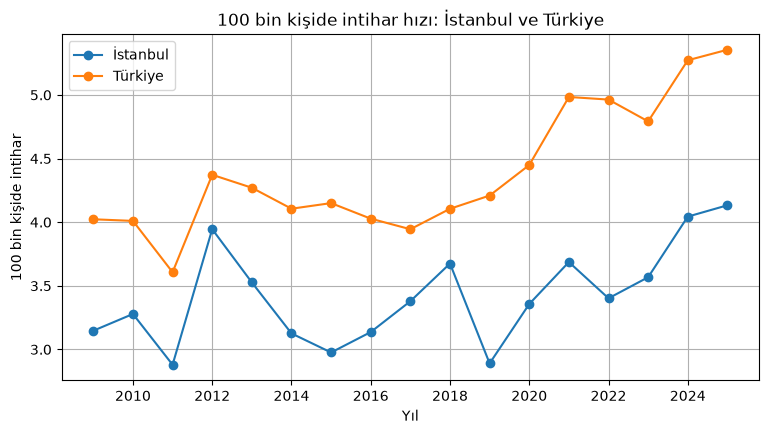

In [6]:
plt.plot(veri["yil"], veri["istanbul_hiz"], marker="o", label="İstanbul")
plt.plot(veri["yil"], veri["turkiye_hiz"], marker="o", label="Türkiye")

plt.title("100 bin kişide intihar hızı: İstanbul ve Türkiye")
plt.xlabel("Yıl")
plt.ylabel("100 bin kişide intihar")
plt.legend()
plt.show()

**Yorum:** Mavi çizgi hiçbir yıl turuncu çizgiyi geçmiyor. İki çizgi aynı yönde hareket ediyor (ikisi de son yıllarda yükseliyor) ama İstanbul sürekli aşağıda.

**Soru 1'in cevabı:** Hipotez **çürütüldü**. Verilere göre İstanbul'un kaba intihar hızı Türkiye ortalamasından yüksek değil, düşük.
Not: Hipotezdeki sebepleri (stres, yaşam pahalılığı) bu veriyle ölçemem; yalnızca "sonuç doğru mu?" kısmını test ettim.

## 4. Soru 2: Erkek/kadın oranı zaman içinde nasıl değişmiş?

Önce yıllara göre erkek ve kadın vaka sayılarını **üst üste** (yığılmış) çubuk grafikle göstereceğim. Böylece hem toplamın hem de dağılımın nasıl değiştiğini aynı anda görebilirim.
`bottom` ayarı kadın çubuklarını erkek çubuklarının üstüne getirir.

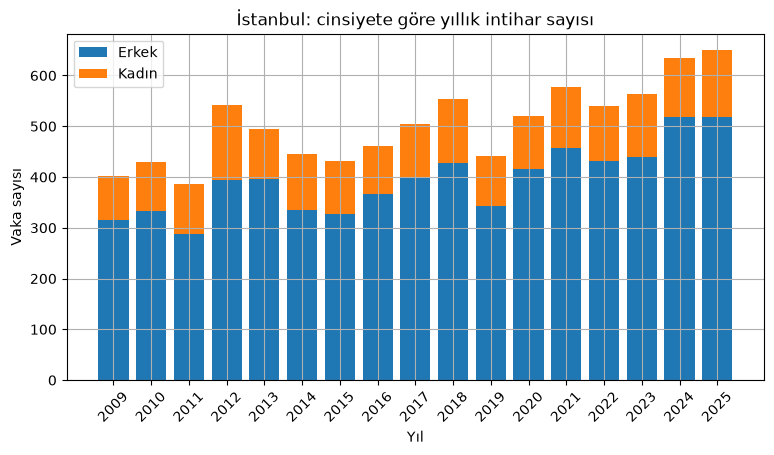

In [7]:
plt.bar(veri["yil"], veri["istanbul_erkek"], label="Erkek")
plt.bar(veri["yil"], veri["istanbul_kadin"], bottom=veri["istanbul_erkek"], label="Kadın")

plt.title("İstanbul: cinsiyete göre yıllık intihar sayısı")
plt.xticks(veri["yil"], rotation=45)       # her yılı tam sayı olarak yaz
plt.xlabel("Yıl")
plt.ylabel("Vaka sayısı")
plt.legend()
plt.show()

**Yorum:** Her yıl vakaların büyük çoğunluğu erkek. Toplam vaka sayısı arttıkça erkek kısmı daha çok büyümüş gibi görünüyor.
Bunu rakamla kontrol etmek için **erkek/kadın oranını** hesaplıyorum (ör. 4 çıkarsa her 1 kadına karşılık 4 erkek vaka var demektir).
Ayrıca ilk 5 yılın ve son 5 yılın ortalamasını karşılaştırıyorum. `head(5)` ilk 5 satırı, `tail(5)` son 5 satırı alır.

In [8]:
veri["erkek_kadin_orani"] = veri["istanbul_erkek"] / veri["istanbul_kadin"]
veri["kadin_payi"] = veri["istanbul_kadin"] / veri["istanbul_toplam"] * 100   # yüzde

print("Tüm dönem erkek/kadın oranı:", round(veri["istanbul_erkek"].sum() / veri["istanbul_kadin"].sum(), 2))
print("Tüm dönem kadın payı (%):", round(veri["istanbul_kadin"].sum() / veri["istanbul_toplam"].sum() * 100, 1))
print()
print("İlk 5 yıl (2009-2013) ortalama oran:", round(np.mean(veri["erkek_kadin_orani"].head(5)), 2))
print("Son 5 yıl (2021-2025) ortalama oran:", round(np.mean(veri["erkek_kadin_orani"].tail(5)), 2))
print()
en_dusuk = veri.loc[veri["erkek_kadin_orani"].idxmin()]
en_yuksek = veri.loc[veri["erkek_kadin_orani"].idxmax()]
print("En düşük oran:", int(en_dusuk["yil"]), "->", round(en_dusuk["erkek_kadin_orani"], 2))
print("En yüksek oran:", int(en_yuksek["yil"]), "->", round(en_yuksek["erkek_kadin_orani"], 2))

Tüm dönem erkek/kadın oranı: 3.58
Tüm dönem kadın payı (%): 21.8

İlk 5 yıl (2009-2013) ortalama oran: 3.33
Son 5 yıl (2021-2025) ortalama oran: 3.96

En düşük oran: 2012 -> 2.69
En yüksek oran: 2024 -> 4.51


**Yorum:** Tüm dönemde her kadın vakasına karşılık yaklaşık **3,6 erkek vakası** var; kadınların payı yaklaşık %22. İlk 5 yılda oran ortalama 3,33 iken son 5 yılda 3,96'ya çıkmış,
yani erkek ağırlığı bir miktar artmış. Ancak oran yıldan yıla çok oynuyor (en düşük 2012'de 2,69, en yüksek 2024'te 4,51). Bu yüzden "kesin bir artış var" demek yerine
**"hafif bir artış eğilimi var ama dalgalanma büyük"** demek daha dürüst olur. Grafikle bakalım; kesikli çizgi tüm dönemin ortalamasıdır.

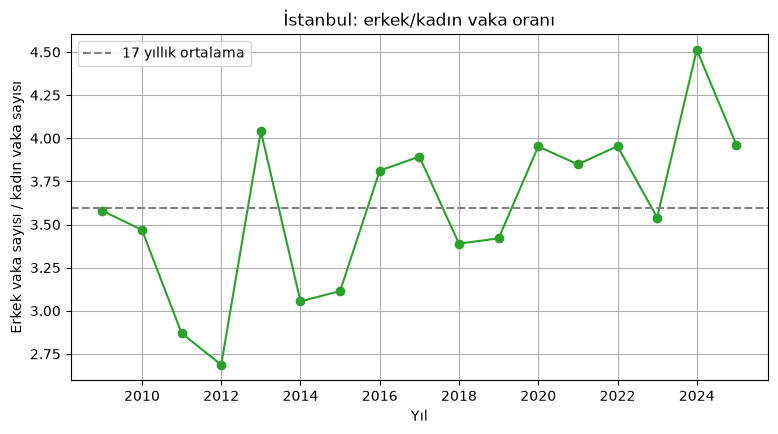

In [9]:
plt.plot(veri["yil"], veri["erkek_kadin_orani"], marker="o", color="tab:green")
plt.axhline(np.mean(veri["erkek_kadin_orani"]), linestyle="--", color="gray", label="17 yıllık ortalama")

plt.title("İstanbul: erkek/kadın vaka oranı")
plt.xlabel("Yıl")
plt.ylabel("Erkek vaka sayısı / kadın vaka sayısı")
plt.legend()
plt.show()

**Soru 2'nin cevabı:** İstanbul'da vakaların yaklaşık dörtte üçünden fazlası erkek. Erkek/kadın oranı 2009-2025 arasında 2,7 ile 4,5 arasında dalgalanmış;
son yıllarda ortalamanın üstünde seyrediyor. Uzun dönemli net bir yön söylemek için 17 yıl ve bu kadar dalgalanma yeterli değil.

## 5. Soru 3: Vakalar hangi yaş grubunda yoğunlaşıyor?

Yaş sütunlarının bir kısmı 5 yıllık gruplar (15-19, 20-24 ...), ama ilk grup (0-14) ve son grup (75 ve üstü) farklı genişlikte. Genişlik farklı olunca
sütunları adil kıyaslayamam. Bu yüzden **en yoğun yaş grubunu** bulurken yalnızca 5 yıllık eşit genişlikteki grupları (15-19 ... 70-74) alıyorum.
`drop` ile istemediğim sütunları çıkarıyor, `sum` ile 17 yılın toplamını alıyorum.

En çok vaka görülen yaş grubu: yas_25_29
Bu grubun payı (%): 14.3


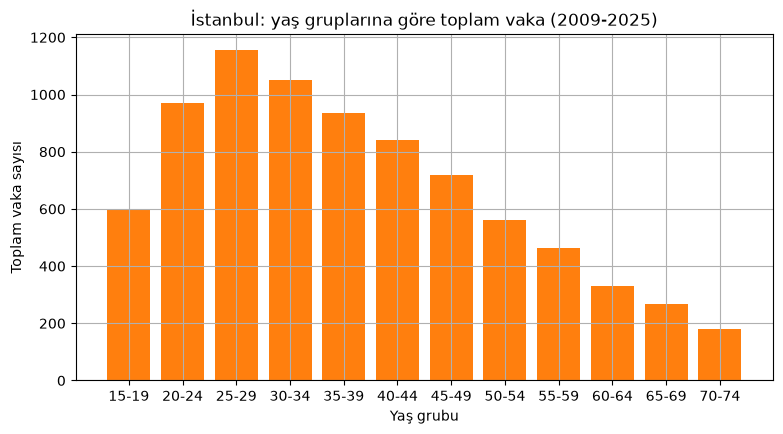

In [10]:
yas_sutunlari = veri.filter(like="yas_").drop(columns=["yas_0_14", "yas_75_ustu", "yas_bilinmeyen"])
yas_toplamlari = yas_sutunlari.sum()          # her yaş grubu için 17 yıllık toplam vaka

# Grafikte "yas_15_19" yerine "15-19" yazsın diye etiketleri düzeltiyorum
etiketler = []
for ad in yas_toplamlari.index:
    etiketler.append(ad.replace("yas_", "").replace("_", "-"))

print("En çok vaka görülen yaş grubu:", yas_toplamlari.idxmax())
print("Bu grubun payı (%):", round(yas_toplamlari.max() / yas_toplamlari.sum() * 100, 1))

plt.bar(etiketler, yas_toplamlari.values, color="tab:orange")
plt.title("İstanbul: yaş gruplarına göre toplam vaka (2009-2025)")
plt.xlabel("Yaş grubu")
plt.ylabel("Toplam vaka sayısı")
plt.show()

**Yorum:** Vakalar en çok **25-29 yaş** grubunda (yaklaşık %14), ardından 30-34 ve 20-24 yaş gruplarında görülüyor. Sayılar 25-29'dan sonra düzenli olarak azalıyor.
Yani vakalar genç ve orta yaşlarda yoğunlaşıyor. Burada önemli bir not: bu bir **vaka sayısı**, risk oranı değil. Bir yaş grubunun nüfusu çok kalabalıksa vaka sayısı
doğal olarak yüksek çıkar. Nüfus verisi olmadığı için "hangi yaş grubu en riskli" diyemem.

Şimdi **genç/yaşlı dağılımı zamanla değişmiş mi** sorusuna bakıyorum. 5 yıllık grupları 3 büyük gruba topluyorum. Bunun için bir **sözlük** kullanıyorum:
anahtarlar yeni grup adları, değerler ise o gruba girecek sütunların **listesi**.

In [11]:
yas_gruplari = {
    "0-29 yaş": ["yas_0_14", "yas_15_19", "yas_20_24", "yas_25_29"],
    "30-49 yaş": ["yas_30_34", "yas_35_39", "yas_40_44", "yas_45_49"],
    "50 yaş ve üstü": ["yas_50_54", "yas_55_59", "yas_60_64", "yas_65_69", "yas_70_74", "yas_75_ustu"],
}

# Her grup için yıllık vaka sayısını hesapla
yas_tablo = pd.DataFrame({"yil": veri["yil"]})
for grup_adi, sutunlar in yas_gruplari.items():
    yas_tablo[grup_adi] = veri[sutunlar].sum(axis=1)

# Yaşı bilinen vakalara göre yüzde payı
yas_tablo["bilinen_toplam"] = yas_tablo[list(yas_gruplari)].sum(axis=1)
for grup_adi in yas_gruplari:
    yas_tablo[grup_adi + " (%)"] = yas_tablo[grup_adi] / yas_tablo["bilinen_toplam"] * 100

yas_tablo[["yil", "0-29 yaş (%)", "30-49 yaş (%)", "50 yaş ve üstü (%)"]].round(1)

,yil,0-29 yaş (%),30-49 yaş (%),50 yaş ve üstü (%)
0,2009,30.0,40.3,29.7
1,2010,33.8,41.0,25.2
2,2011,34.6,33.5,31.9
3,2012,36.4,39.7,23.9
4,2013,33.5,39.9,26.6
5,2014,34.3,42.2,23.5
6,2015,30.8,42.9,26.3
7,2016,32.5,43.0,24.5
8,2017,31.9,40.7,27.4
9,2018,31.1,43.2,25.7


**Yorum:** Tablodaki yıllara bakınca 30-49 yaş grubunun payı çoğu yıl %40-45 aralığında. 50 yaş ve üstünün payı 2009-2011'de %25-32 iken 2022-2024'te %20-21'e inmiş,
2025'te ise %25'e çıkmış. 0-29 yaş grubunun payı ise yıldan yıla %28-39 arasında dalgalanıyor.

**Soru 3'ün cevabı:** Vakalar en çok 20-34 yaş aralığında yoğunlaşıyor (zirve 25-29). Orta yaş (30-49) grubu vakaların yaklaşık %40-45'ini oluşturuyor; 50 yaş üstünün payı
son yıllarda biraz düşmüş görünüyor ama dalgalanma büyük olduğu için net bir yön söylemek zor. Bunlar vaka payıdır, risk oranı değildir; nüfusun yaş yapısı da değiştiği için
payın değişmesi tek başına riskin değiştiğini göstermez.

## 6. Soru 4: En sık görülen intihar şekilleri nelerdir ?

Önce 17 yıl boyunca her şeklin toplam vaka sayısını ve toplam içindeki payını hesaplıyorum. `sort_values` büyükten küçüğe sıralar.
Payı, her şeklin 17 yıllık toplamını 17 yıllık toplam vaka sayısına bölerek hesaplıyorum.

In [12]:
# "Diğer" bir yöntem değil, çeşitli yöntemlerin toplandığı bir torba olduğu için sıralamadan çıkarıyorum
sekil_toplamlari = veri.filter(like="sekil_").drop(columns=["sekil_diger"]).sum().sort_values(ascending=False)
sekil_paylari = sekil_toplamlari / veri["istanbul_toplam"].sum() * 100

# Grafiklerde düzgün Türkçe yazsın diye sütun adlarına karşılık gelen etiketleri bir sözlükte tutuyorum
sekil_etiket = {
    "sekil_asarak": "Asarak",
    "sekil_atesli_silah": "Ateşli silah",
    "sekil_yuksekten_atlayarak": "Yüksekten atlayarak",
    "sekil_suya_atlayarak": "Suya atlayarak",
    "sekil_kimyevi_madde": "Kimyevi madde",
}

print("En sık görülen 5 şekil")
print(sekil_paylari.head(5).round(1))

En sık görülen 5 şekil
sekil_asarak                 47.6
sekil_atesli_silah           20.6
sekil_yuksekten_atlayarak    17.7
sekil_suya_atlayarak          3.4
sekil_kimyevi_madde           3.3
dtype: float64


**Yorum:** En sık görülen üç şekil sırasıyla `sekil_asarak` (%47,6), `sekil_atesli_silah` (%20,6) ve `sekil_yuksekten_atlayarak` (%17,7). Bu üç şekil vakaların yaklaşık %86'sını oluşturuyor.
(Not: "Diğer" kategorisi bir yöntem olmadığı için sıralamaya almadım; payı yaklaşık %4,6.)
Grafiğe dökelim. Yatay çubuk grafik (`barh`) uzun isimler için daha okunaklıdır.

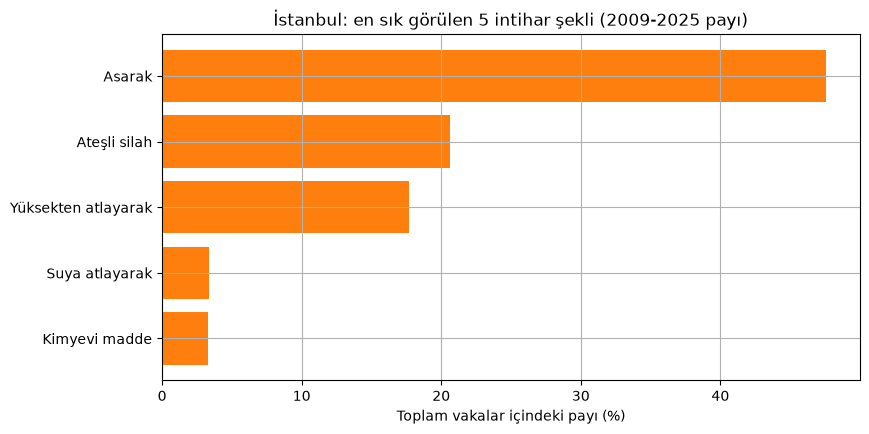

In [13]:
ilk_5 = sekil_paylari.head(5).sort_values()      # grafikte en büyük üstte olsun diye küçükten büyüğe diziyorum

etiketler = []
for ad in ilk_5.index:
    etiketler.append(sekil_etiket[ad])

plt.barh(etiketler, ilk_5.values, color="tab:orange")
plt.title("İstanbul: en sık görülen 5 intihar şekli (2009-2025 payı)")
plt.xlabel("Toplam vakalar içindeki payı (%)")
plt.show()

**Soru 4'ün cevabı:** İstanbul'da en sık görülen şekil asarak (yaklaşık %48). Ardından ateşli silah (yaklaşık %21) ve yüksekten atlayarak (yaklaşık %18) geliyor.
Bu çalışmada şekilleri yıllara göre ayrıca incelemedim; cinsiyete göre farklılaşmayı ise cevaplayamıyorum, çünkü TÜİK şekil tablosu cinsiyete göre ayrılmamış.

## 7. Genel sonuç

| Soru | Kısa cevap |
|---|---|
| 1. İstanbul'un hızı Türkiye'den yüksek mi? | **Hayır.** 17 yılın hiçbirinde yüksek değil; ortalama 3,42 (Türkiye 4,39). Hipotez çürütüldü. |
| 2. Erkek/kadın oranı | Erkekler vakaların yaklaşık %78'i. Oran 2,7-4,5 arasında dalgalanıyor; son 5 yılda ilk 5 yıla göre biraz yüksek (3,96 ve 3,33). |
| 3. Yaş grubu | Vakalar en çok 25-29 yaşta ve çevresinde yoğunlaşıyor. 30-49 yaş payı genelde %40-45; 50 yaş üstü payı son yıllarda biraz düşmüş ama dalgalanma büyük. |
| 4. Yöntem | En sık şekil asarak (yaklaşık %48), ardından ateşli silah (%21) ve yüksekten atlayarak (%18). Cinsiyete göre ayrım veride yok. |

**Hikâyenin özeti:** "İstanbul'da hayat çok zor, o halde intihar oranı da yüksektir" düşüncesi sezgisel olarak mantıklı görünüyor, ama veri bunu desteklemiyor. İstanbul'un hızı Türkiye'nin
yaklaşık %78'i kadar. Vakaların büyük kısmı erkek ve 20-34 yaş çevresinde.

**Sınırlılıklar (dürüst olmak gerekirse):**
- Bu **kaba hız**; yaş ve cinsiyet yapısı hesaba katılmadı. İstanbul'un nüfus yapısı Türkiye'den farklıysa farkın bir kısmı bundan olabilir.
- Hipotezdeki **nedenleri** (stres, yaşam pahalılığı) ölçemedim; yalnızca sonucun verideki karşılığını test ettim. Hipotezin "sonucu" verilerle uyuşmuyor, ama "nedeni" hakkında kesin bir şey söyleyemem.
- Yaş ve cinsiyet analizleri **vaka paylarıdır**, risk oranı değildir (grup nüfusları elimde yok).
- TÜİK 2012'de kayıt kapsamını genişletti; 2009-2011 ile sonrasını tek bir uzun trend gibi okumamak gerekir.
- Bu çalışma tanımlayıcıdır; "neden?" sorusuna cevap vermez. 17 yıllık küçük bir seriyle çalıştığım için "ilk 5 yıl / son 5 yıl" karşılaştırmaları kesin kanıt değil, yaklaşık bir fikir verir.

**Bu çalışmada öğrendiklerim:** Hipotezin kulağa mantıklı gelmesi onun doğru olduğunu göstermiyor; veriye bakmak gerekiyor. Ayrıca bir sayıyı yorumlamadan önce verinin nasıl toplandığına (eksik değerler, kategori
tanımları) bakmak gerekiyor; aksi hâlde artış gibi görünen şey aslında kayıt değişikliği olabiliyor.

Kendiniz ya da çevrenizde biri için destek arıyorsanız **112 Acil Çağrı Merkezi** arayabilirsiniz.

Dosyayı okuduğunuz için teşekkürler.

Kaynak : https://veriportali.tuik.gov.tr/tr/press/58233